# EDA Amazon Beauty 2014 — Tuần 1 của B

- Nội dung: độ dài chuỗi, long-tail, độ thưa, thống kê thiếu metadata và ví dụ mô tả sản phẩm.
- Chọn kernel từ venv Python 3.12 rồi Run All.
- Dùng chung src/eda.py và configs/eda.json; hình và báo cáo xuất vào reports/.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'configs' / 'preprocessing.json').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.eda import analyze_data, clean_text, write_eda_report

config_path = ROOT / 'configs' / 'eda.json'
config = json.loads(config_path.read_text(encoding='utf-8'))
analysis = analyze_data(ROOT / 'data' / 'processed', ROOT / 'data' / 'splits', seed=config['seed'], head_fraction=config['head_fraction'])
stats = analysis['summary']
print('Manifest dữ liệu hợp lệ; seed lấy ví dụ:', config['seed'])

Manifest dữ liệu hợp lệ; seed lấy ví dụ: 42


## 1. Quy mô dữ liệu và cách đếm

Dùng tập sau tiền xử lý. Mỗi user có một nhãn validation và một nhãn test. Train + validation bằng 176.139; không ép số tương tác gốc về mốc này.

In [2]:
display(pd.DataFrame({'giá_trị': {key: stats[key] for key in ['users', 'items', 'interactions', 'train_interactions', 'validation_targets', 'test_targets', 'unique_user_item_pairs']}}))
print('Train + validation:', stats['train_interactions'] + stats['validation_targets'])
print(f"Độ thưa: {stats['sparsity']:.6%}")
print('Tương tác dư theo cặp user-item:', stats['duplicate_user_item_events'])
print('Tương tác dư khi gộp theo user-timestamp:', stats['tied_user_timestamp_events'])

,giá_trị
users,22363
items,12101
interactions,198502
train_interactions,153776
validation_targets,22363
test_targets,22363
unique_user_item_pairs,198502


Train + validation: 176139
Độ thưa: 99.926648%
Tương tác dư theo cặp user-item: 0
Tương tác dư khi gộp theo user-timestamp: 77402


## 2. Phân bố độ dài chuỗi

- Giữ toàn bộ train cho khai phá mẫu.
- Lịch sử đầu vào mô hình lấy tối đa 50 item cuối.

In [3]:
display(pd.DataFrame({name: stats[name] for name in ['sequence_length_full', 'sequence_length_train', 'train_item_frequency']}).T)

,count,min,median,p90,p95,max,mean
sequence_length_full,22363.0,5.0,6.0,14.0,21.0,204.0,8.876358
sequence_length_train,22363.0,3.0,4.0,12.0,19.0,202.0,6.876358
train_item_frequency,12101.0,0.0,7.0,27.0,44.0,369.0,12.707710


## 3. Xuất hình và báo cáo EDA

- Lệnh ngoài notebook: python -m src.eda.
- Xuất hai hình: độ dài chuỗi và long-tail.
- Provenance ghi checksum dữ liệu và hình đầu ra.

In [4]:
figures = write_eda_report(analysis, ROOT / 'reports', config=config, config_path=config_path)
print('Đã tạo:', [path.name for path in figures])

Đã tạo: ['eda_sequence_lengths.png', 'eda_long_tail.png']


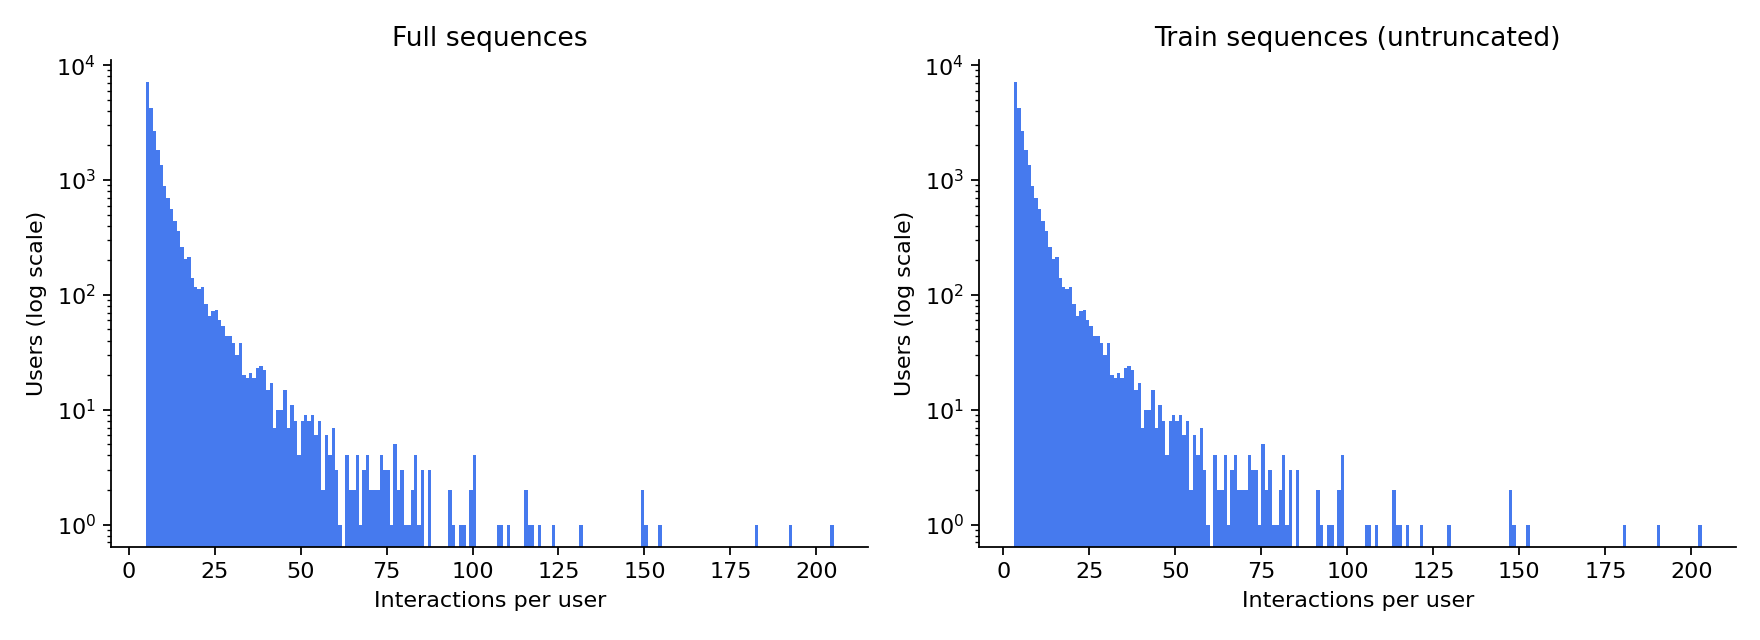

In [5]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'eda_sequence_lengths.png'), width=1000))

## 4. Long-tail theo train

Head = ceil(20% × số item catalog), xếp theo số tương tác train, hòa thì ID tăng dần. Độ thưa dùng số cặp user–item duy nhất. Item có tần suất train bằng 0 vẫn nằm trong catalog.

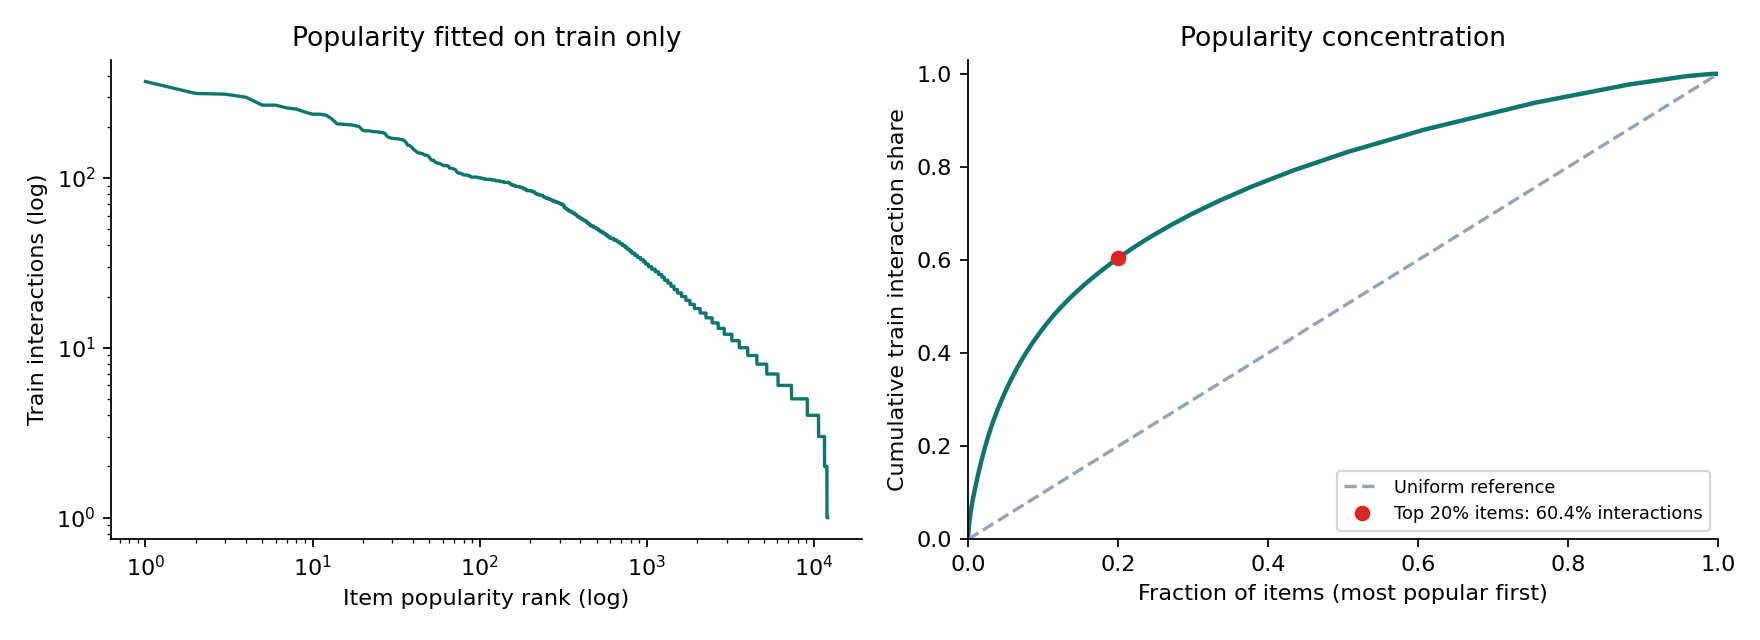

Head gồm 2,421 item, chiếm 60.39% tương tác train


In [6]:
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'eda_long_tail.png'), width=1000))
print(f"Head gồm {stats['head_items']:,} item, chiếm {stats['head_train_interaction_share']:.2%} tương tác train")

## 5. Tình trạng thiếu metadata

- Thống kê trên toàn bộ item sau tiền xử lý.
- Phân biệt thiếu cả bản ghi với thiếu từng trường; metadata_missing chỉ đánh dấu thiếu cả bản ghi.
- Đây là thống kê dữ liệu, chưa áp dụng điền thiếu hay tạo văn bản fallback.

In [7]:
metadata_rows = [
    {'nội_dung_thiếu': 'Cả bản ghi metadata', 'số_item': stats['metadata_missing_items'],
     'tỷ_lệ': stats['metadata_missing_items'] / stats['items']},
    *[{'nội_dung_thiếu': field, 'số_item': count, 'tỷ_lệ': stats['missing_field_ratios'][field]}
      for field, count in stats['missing_fields'].items()],
    {'nội_dung_thiếu': 'Cả title và description', 'số_item': stats['missing_title_and_description'],
     'tỷ_lệ': stats['missing_title_and_description'] / stats['items']},
]
display(pd.DataFrame(metadata_rows))
display(Markdown(
    f"- **{stats['missing_fields']['description']:,} item** thiếu description → nội dung có thể ít thông tin hơn.\n"
    f"- **{stats['missing_description_with_title']:,} item** còn title có thể dùng title + category; "
    f"**{stats['missing_title_and_description']:,} item** thiếu cả hai cần thông tin còn lại, tối thiểu là category nếu có.\n"
    f"- **{stats['missing_fields']['brand']:,} item** thiếu brand → giữ trạng thái thiếu, không tự đoán thương hiệu.\n"
    "- Pipeline hiện chưa tạo văn bản fallback; phải xử lý trước khi encode."
))

,nội_dung_thiếu,số_item,tỷ_lệ
0,Cả bản ghi metadata,0,0.000000
1,title,7,0.000578
2,brand,2098,0.173374
3,categories,0,0.000000
4,description,941,0.077762
5,Cả title và description,7,0.000578


- **941 item** thiếu description → nội dung có thể ít thông tin hơn.
- **934 item** còn title có thể dùng title + category; **7 item** thiếu cả hai cần thông tin còn lại, tối thiểu là category nếu có.
- **2,098 item** thiếu brand → giữ trạng thái thiếu, không tự đoán thương hiệu.
- Pipeline hiện chưa tạo văn bản fallback; phải xử lý trước khi encode.

## 6. Ví dụ mô tả sản phẩm

In [8]:
display(pd.DataFrame([{'item_id': row['item_id'], 'asin': row['asin'], 'title': clean_text(row['metadata'].get('title')), 'brand': clean_text(row['metadata'].get('brand')), 'description_excerpt': clean_text(row['metadata'].get('description'))[:240]} for row in analysis['examples']]))

,item_id,asin,title,brand,description_excerpt
0,10477,B004SUPEOK,one 'n only Argan Oil Hydrating Mask Derived f...,one 'n only,The one 'n only Argan Oil Hydrating Mask conta...
1,1825,B003U4LGV0,"Blemish Control Green Tea Scrub by St. Ives, 4...",St. Ives,
2,410,B001UE60E0,DHC Deep Cleansing Oil 6.7fl.oz./200ml,DHC,Superstar. Try this amazing cleanser and you'l...
3,4507,B002RGRJC2,Moroccanoil Moisture Repair Shampoo & Conditio...,Moroccanoil,Moisture Repair Shampoo and Conditioner are fo...


## 7. Nhận xét từ EDA

Số liệu được tính lại từ dữ liệu đã chia.

In [9]:
display(Markdown(
    f"- Độ thưa **{stats['sparsity']:.4%}** → ít bằng chứng đồng xuất hiện; luật mua kèm có thể kém ổn định.\n"
    f"- Trung vị train **{stats['sequence_length_train']['median']:.0f} item** → mẫu mua kèm dài có thể khó đạt support.\n"
    f"- Top 20% item chiếm **{stats['head_train_interaction_share']:.2%}** tương tác train → mô hình có thể thiên về sản phẩm phổ biến.\n"
    f"- **{stats['missing_fields']['description']:,} item** thiếu description → cần fallback trước khi encode; pipeline hiện chưa thực hiện.\n"
    "- Các hệ quả với mô hình cần được kiểm chứng.\n"
    "- Nhận xét chi tiết: reports/data_quality.md."
))

- Độ thưa **99.9266%** → ít bằng chứng đồng xuất hiện; luật mua kèm có thể kém ổn định.
- Trung vị train **4 item** → mẫu mua kèm dài có thể khó đạt support.
- Top 20% item chiếm **60.39%** tương tác train → mô hình có thể thiên về sản phẩm phổ biến.
- **941 item** thiếu description → cần fallback trước khi encode; pipeline hiện chưa thực hiện.
- Các hệ quả với mô hình cần được kiểm chứng.
- Nhận xét chi tiết: reports/data_quality.md.

## 8. Tái chạy và kiểm chứng

- python -m src.preprocessing --verify-only
- python -m src.eda
- python -m pytest -q

Quy ước dữ liệu: docs/data_contract.md. Phân tích chất lượng semantic ID tuần 1 còn chờ file từ A.